# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 
import matplotlib.pyplot as plt

from aitlas.datasets import VALIDObjectDetectionDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects with bounding boxes

Total number of patches: 6689


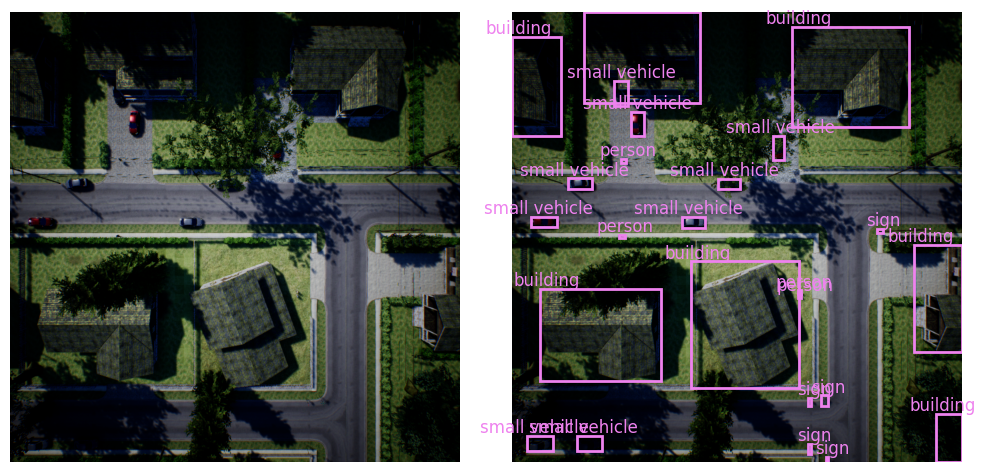

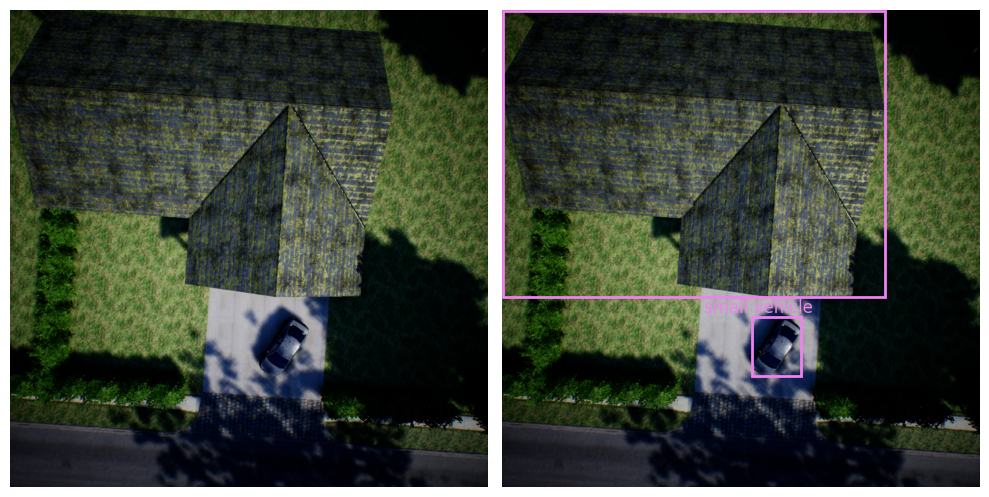

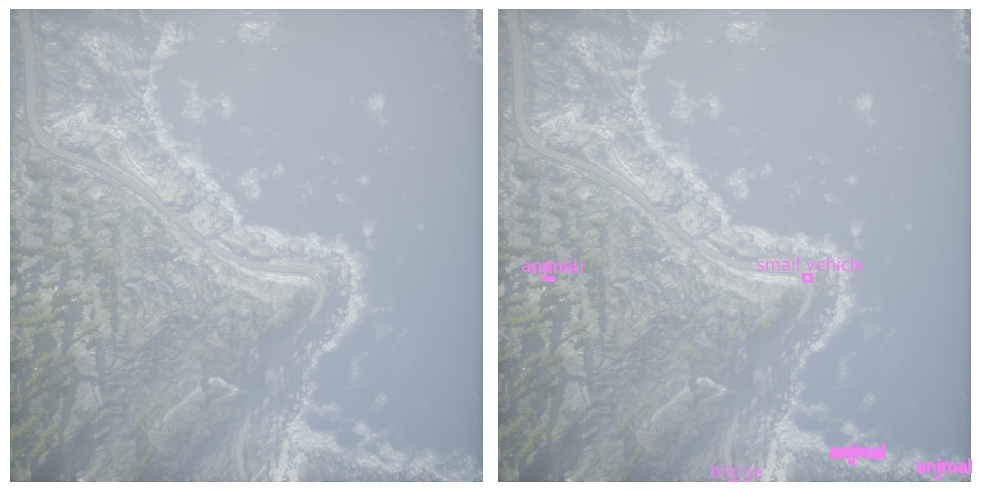

In [7]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/valid_object_detection/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/valid_object_detection/label/",
}
dataset = VALIDObjectDetectionDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(100);
dataset.show_image(780);
dataset.show_image(123);

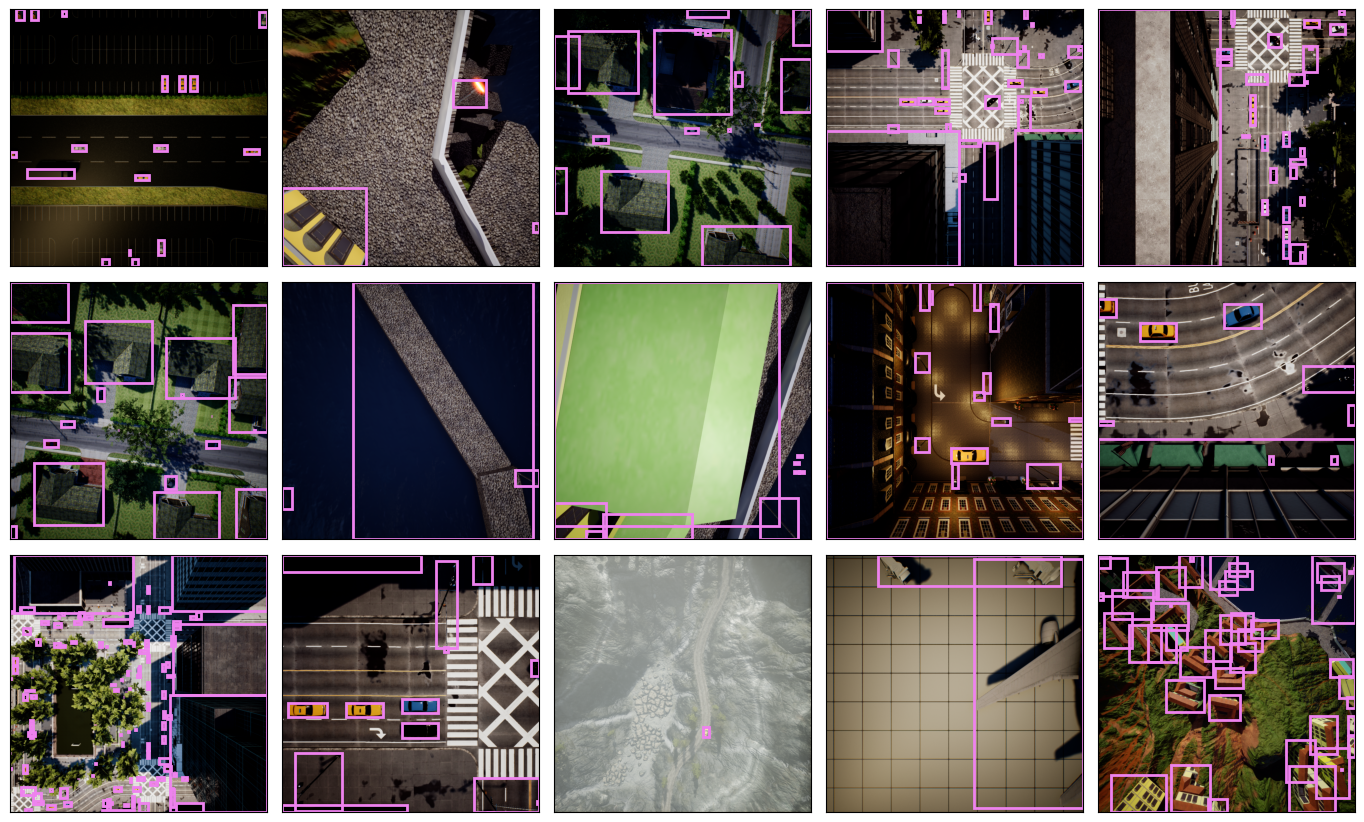

In [ ]:
dataset.show_batch(15);

In [8]:
dataset.data_distribution_table()

,Label,Count
0,animal,7270
1,bridge,561
2,building,29456
3,busstop,3103
4,chair,8766
5,garbagebin,3250
6,harbor,616
7,lamp,20526
8,largevehicle,2021
9,person,16889


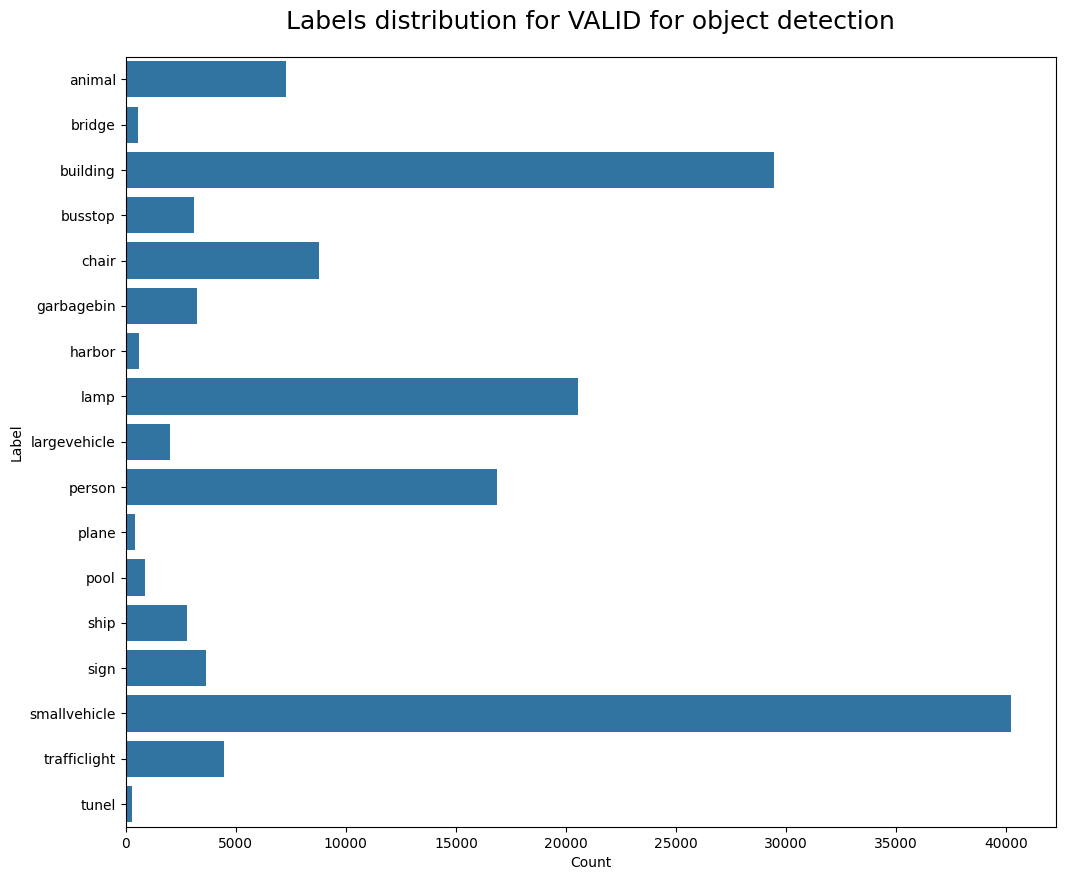

In [9]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "data_dir": "/home/dragik/data/FAIR_EO/valid_object_detection/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/valid_object_detection/label/",
    "csv_file": "/home/dragik/data/FAIR_EO/valid_object_detection/valid_train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = VALIDObjectDetectionDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 5352


## Create the model

In [ ]:
epochs = 5
model_directory = "/home/dragik/data/FAIR_EO/experiments/valid_object_detection/"
model_config = {
    "num_classes": 31,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-10-01 14:29:53,601 INFO Starting training.
training: 100%|██████████| 335/335 [1:56:19<00:00, 20.83s/it]
2025-10-01 16:26:13,291 INFO epoch: 1, time: 6980, loss:  1.12545
testing on train set: 100%|██████████| 335/335 [1:54:54<00:00, 20.58s/it]  
2025-10-01 18:22:06,917 INFO map:0.32313796877861023, map_50:0.5020098090171814, map_75:0.3764125406742096, map_small:0.21262815594673157, map_medium:0.5638852119445801, map_large:0.5788100957870483, mar_1:0.1959877759218216, mar_10:0.35453689098358154, mar_100:0.3716505467891693, mar_small:0.25171753764152527, mar_medium:0.6236998438835144, mar_large:0.6243554353713989, map_per_class:tensor(0.6518), tensor(0.4267), tensor(0.0560), tensor(0.5009), tensor(0.4856), tensor(0.6804), tensor(0.0311), tensor(0.0874), tensor(0.0207), tensor(0.0105), tensor(0.0370), tensor(0.3343), tensor(0.2203), tensor(0.1353), tensor(0.6474), tensor(0.7145), tensor(0.4536), mar_100_per_class:tensor(0.6994), tensor(0.4812), tensor(0.0750), tensor(0.5556), tensor

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "/home/dragik/data/FAIR_EO/valid_object_detection/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/valid_object_detection/label/",
    "csv_file": "/home/dragik/data/FAIR_EO/valid_object_detection/valid_val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = VALIDObjectDetectionDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/valid_object_detection/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 669


2025-10-02 11:01:41,261 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/VALID_object_detection/checkpoint.pth.tar
2025-10-02 11:01:41,592 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/VALID_object_detection/checkpoint.pth.tar at epoch 6
testing on test set: 100%|██████████| 84/84 [15:29<00:00, 11.07s/it] 


[{'map': 0.47102585434913635,
  'map_50': 0.6449525952339172,
  'map_75': 0.5343998074531555,
  'map_small': 0.3723480701446533,
  'map_medium': 0.7149289846420288,
  'map_large': 0.799466609954834,
  'mar_1': 0.26421016454696655,
  'mar_10': 0.4814828336238861,
  'mar_100': 0.5033546090126038,
  'mar_small': 0.40049442648887634,
  'mar_medium': 0.7414228916168213,
  'mar_large': 0.8414681553840637,
  'map_per_class': [tensor(0.7516),
   tensor(0.6367),
   tensor(0.1511),
   tensor(0.6137),
   tensor(0.6918),
   tensor(0.7679),
   tensor(0.0639),
   tensor(0.1558),
   tensor(0.1034),
   tensor(0.1422),
   tensor(0.0621),
   tensor(0.5044),
   tensor(0.3705),
   tensor(0.5380),
   tensor(0.8312),
   tensor(0.8349),
   tensor(0.7882)],
  'mar_100_per_class': [tensor(0.7980),
   tensor(0.6714),
   tensor(0.1896),
   tensor(0.6498),
   tensor(0.7342),
   tensor(0.8007),
   tensor(0.0922),
   tensor(0.1892),
   tensor(0.1282),
   tensor(0.1653),
   tensor(0.0648),
   tensor(0.5437),
   tens

## Predictions

2025-10-02 11:46:36,014 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/VALID_object_detection/checkpoint.pth.tar
2025-10-02 11:46:36,318 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/VALID_object_detection/checkpoint.pth.tar at epoch 6


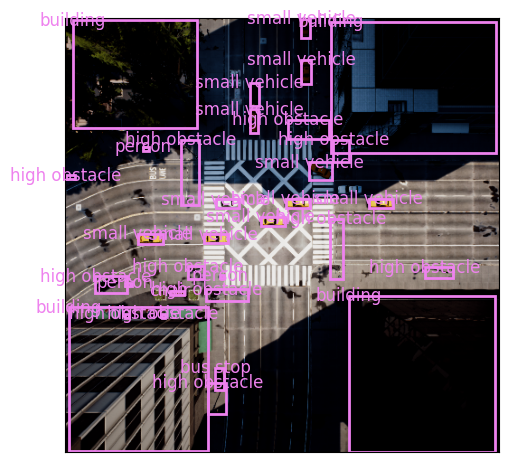

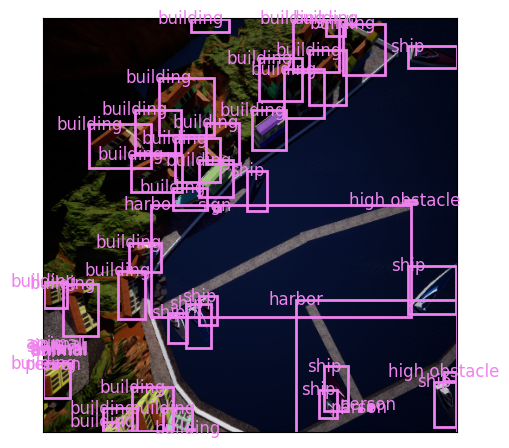

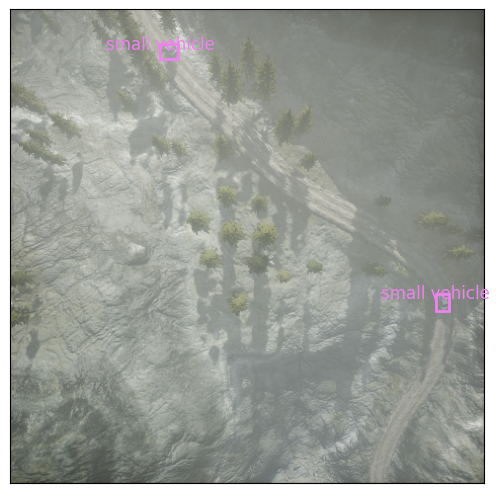

In [ ]:
model_config = {
    "num_classes": 31,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/experiments/valid_object_detection/checkpoint.pth.tar"
labels = ["no-data","tree","plant","road","pavement","land","water","pool","ice","stone","pier rubble","bridge",
        "sign","small vehicle","large vehicle","building","animal","person","chair","fence","garbage bin",
        "low obstacle","telegraph pole","traffic light","bus stop","lamp","high obstacle","tunnel","ship",
        "plane","harbor"]
transform = Resize()
model.load_model(model_path)
plt.rcParams.update({'font.size': 4})

image = image_loader('/home/dragik/data/FAIR_EO/valid_object_detection/images/downtown/50/img_2_0_1552287449608901100.png')[:,:,0:3]
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/valid_object_detection/images/seaside/100/img_2_0_1552118069172620500.png')[:,:,0:3]
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/valid_object_detection/images/mountain/50/img_1_0_1552050875644468200.png')[:,:,0:3]
fig = model.detect_objects(image, labels, transform)